# Mejores Modelos — Análisis SHAP por Especie

Análisis del efecto de cada especie sobre la predicción de carbono para los mejores
modelos base (locales y globales) de cada caso.

Para cada modelo se calcula el SHAP medio con signo de la columna OHE de cada
`especie_id`, usando únicamente las muestras donde esa especie está activa.
Los nombres proceden de la base de datos.

| Caso | Modelos |
|------|---------|
| IFN2 / c4 | LightGBM global, LightGBM local |
| IFN2 / carbono\_bruto4 | CatBoost global, LightGBM global, LightGBM local |
| IFN3 / c4 | LightGBM local, GBDT global |
| IFN3 / carbono\_bruto4 | LightGBM local, CatBoost global |

In [1]:
import os
import re
import gc
import sys
import warnings
from pathlib import Path

import joblib
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator
from IPython.display import Image as IPImage, display as ipy_display

import shap
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from scipy.stats import gaussian_kde
from matplotlib.colors import Normalize
import time

warnings.filterwarnings('ignore')
%matplotlib inline

print('Imports OK')
from tqdm.auto import tqdm


<conda_env>/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports OK


In [2]:
# =============================================================================
# Clases PyTorch — necesarias para deserializar modelos .joblib
# =============================================================================

def cast_to_str(X):
    return pd.DataFrame(X).astype(str).values


class PyTorchMLPDropout(nn.Module):
    def __init__(self, input_dim, hidden_layer_sizes=(100,), activation='relu',
                 dropout_rate=0.2, use_batchnorm=True):
        super().__init__()
        layers = []
        in_dim = input_dim
        if activation == 'relu':         act_fn = nn.ReLU
        elif activation == 'tanh':       act_fn = nn.Tanh
        elif activation == 'leaky_relu': act_fn = lambda: nn.LeakyReLU(0.1)
        else:                            act_fn = nn.ReLU
        for h in hidden_layer_sizes:
            layers.append(nn.Linear(in_dim, h))
            if use_batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(act_fn())
            if dropout_rate > 0: layers.append(nn.Dropout(dropout_rate))
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


class MLPRegressorTorch(BaseEstimator, RegressorMixin):
    def __init__(self, hidden_layer_sizes=(100,), activation='relu', solver='adam',
                 alpha=1e-4, learning_rate_init=1e-3, max_iter=200, batch_size=256,
                 dropout_rate=0.2, use_batchnorm=True, device='cpu', verbose=False):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.activation = activation
        self.solver = solver
        self.alpha = alpha
        self.learning_rate_init = learning_rate_init
        self.max_iter = max_iter
        self.batch_size = batch_size
        self.dropout_rate = dropout_rate
        self.use_batchnorm = use_batchnorm
        self.device = device
        self.verbose = verbose
        self.model_ = None

    def predict(self, X):
        if self.model_ is None:
            raise RuntimeError('Model not fitted')
        self.model_.eval()
        self.model_.to(self.device)
        X_t = torch.tensor(pd.DataFrame(X).values, dtype=torch.float32).to(self.device)
        with torch.no_grad():
            return self.model_(X_t).cpu().numpy().flatten()


import __main__
__main__.cast_to_str = cast_to_str
__main__.PyTorchMLPDropout = PyTorchMLPDropout
__main__.MLPRegressorTorch = MLPRegressorTorch

print('Clases PyTorch OK — spoofing listo')

Clases PyTorch OK — spoofing listo


In [3]:
# =============================================================================
# Rutas y configuración
# =============================================================================

BASE = Path('../../../')

DATA_PATH = BASE / 'data/processed/ifn_entrenamiento_year_agrupado_periodo_completado_2.csv'

# Modelos locales
MODELS_IFN2_C4  = BASE / 'models/artifacts/IFN2/c4/base'
MODELS_IFN2_CB4 = BASE / 'models/artifacts/IFN2/carbono_bruto4/base'
MODELS_IFN3_C4  = BASE / 'models/artifacts/IFN3/c4/base'
MODELS_IFN3_CB4 = BASE / 'models/artifacts/IFN3/carbono_bruto4/base'

# Modelos globales (entrenados con IFN2+3)
MODELS_GLO_C4   = BASE / 'models/artifacts/IFN2-3/c4/base'
MODELS_GLO_CB4  = BASE / 'models/artifacts/IFN2-3/carbono_bruto4/base'

# Salida
OUT_DIR   = BASE / 'figures/mejores_modelos_shap'
CACHE_DIR = OUT_DIR / 'cache'
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

MAPA_PENDIENTE   = {
    'muy suave (<5°)': 0, 'suave (5-10°)': 1, 'moderada (10-15°)': 2,
    'fuerte (15-20°)': 3, 'muy fuerte (20-30°)': 4,
    'escarpada (30-50°)': 5, 'extrema (>50°)': 6
}
MAPA_ORIENTACION = {'N': 0, 'NE': 1, 'E': 2, 'SE': 3, 'S': 4, 'SO': 5, 'O': 6, 'NO': 7}

FEATURES_C4 = [
    'especie_id', 'tipo_especie', 'periodo_agrupado', 'radio', 'ocupa',
    'npies_1', 'npies_2', 'npies_5', 'npies_10', 'npies_15', 'npies_20',
    'npies_25', 'npies_30', 'npies_35', 'npies_40', 'npies_45', 'npies_50',
    'npies_55', 'npies_60', 'npies_65', 'npies_70',
    'estado_id', 'fccarb', 'disesp_id', 'modcomb_id', 'nivel2_id', 'tratmasa_id',
    'rocosidad_id', 'orientacion_cat', 'elevacion', 'pendiente_cat', 'martonneidx_id',
    'skt_mean_primavera', 'pr_sum_primavera', 'skt_std_verano', 'skt_std_primavera',
    'pr_sum_otoño', 'skt_mean_verano', 'pr_sum_verano', 'pr_sum_invierno',
    'gndvi_mean_verano', 'ndii_mean_primavera', 'gndvi_std_primavera', 'evi_mean_primavera'
]
FEATURES_CB4 = [
    'especie_id', 'tipo_especie', 'periodo_agrupado', 'radio', 'ocupa',
    'npies_1', 'npies_2', 'npies_5', 'npies_10', 'npies_15', 'npies_20',
    'npies_25', 'npies_30', 'npies_35', 'npies_40', 'npies_45', 'npies_50',
    'npies_55', 'npies_60', 'npies_65', 'npies_70',
    'estado_id', 'fccarb', 'disesp_id', 'modcomb_id', 'nivel2_id', 'tratmasa_id',
    'rocosidad_id', 'orientacion_cat', 'elevacion', 'pendiente_cat', 'martonneidx_id',
    'gndvi_mean_verano', 'ndii_mean_primavera', 'gndvi_std_primavera', 'evi_mean_primavera'
]
VARS_CATEGORICAS = [
    'especie_id', 'tipo_especie', 'estado_id', 'disesp_id',
    'modcomb_id', 'nivel2_id', 'tratmasa_id', 'rocosidad_id',
    'martonneidx_id', 'orientacion_cat', 'pendiente_cat'
]

# Variables categóricas con orden significativo → color = valor real (no carbono medio)
VARS_ORDINALES = {'rocosidad_id', 'martonneidx_id', 'estado_id', 'tratmasa_id', 'pendiente_cat', 'tipo_especie'}

# Casos a analizar
# Modelos locales: evaluados sobre el test split del inventario correspondiente
# Modelos globales: evaluados sobre su PROPIO test split IFN2+3 (ifn_filter='')
CASOS = [
    {
        'titulo'    : 'NFI2 / c4',
        'target'    : 'c4',
        'unit'      : 'tC/ha',
        'ifn_filter': '2',
        'features'  : FEATURES_C4,
        'modelos'   : [
            {'label': 'LightGBM local (NFI2)', 'path': MODELS_IFN2_C4 / 'LightGBM.joblib', 'name': 'LightGBM_local', 'out_key': 'IFN2_c4_local'},
        ],
        'cache_key'     : 'ifn2_c4',
        'out_key'       : 'IFN2_c4_local',
        'test_idx_path' : BASE / 'models/artifacts/IFN2/c4/base/test_indices_real.joblib',
    },
    {
        'titulo'    : 'NFI2 / carbono\_bruto4',
        'target'    : 'carbono_bruto4',
        'unit'      : 'tC',
        'ifn_filter': '2',
        'features'  : FEATURES_CB4,
        'modelos'   : [
            {'label': 'LightGBM local (NFI2)', 'path': MODELS_IFN2_CB4 / 'LightGBM.joblib', 'name': 'LightGBM_local', 'out_key': 'IFN2_cb4_local'},
        ],
        'cache_key'     : 'ifn2_cb4',
        'out_key'       : 'IFN2_cb4_local',
        'test_idx_path' : BASE / 'models/artifacts/IFN2/carbono_bruto4/base/test_indices_real.joblib',
    },
    {
        'titulo'    : 'NFI3 / c4',
        'target'    : 'c4',
        'unit'      : 'tC/ha',
        'ifn_filter': '3',
        'features'  : FEATURES_C4,
        'modelos'   : [
            {'label': 'LightGBM local (NFI3)', 'path': MODELS_IFN3_C4 / 'LightGBM.joblib', 'name': 'LightGBM_local', 'out_key': 'IFN3_c4_local'},
        ],
        'cache_key'     : 'ifn3_c4',
        'out_key'       : 'IFN3_c4_local',
        'test_idx_path' : BASE / 'models/artifacts/IFN3/c4/base/test_indices_real.joblib',
    },
    {
        'titulo'    : 'NFI3 / carbono\_bruto4',
        'target'    : 'carbono_bruto4',
        'unit'      : 'tC',
        'ifn_filter': '3',
        'features'  : FEATURES_CB4,
        'modelos'   : [
            {'label': 'LightGBM local (NFI3)', 'path': MODELS_IFN3_CB4 / 'LightGBM.joblib', 'name': 'LightGBM_local', 'out_key': 'IFN3_cb4_local'},
        ],
        'cache_key'     : 'ifn3_cb4',
        'out_key'       : 'IFN3_cb4_local',
        'test_idx_path' : BASE / 'models/artifacts/IFN3/carbono_bruto4/base/test_indices_real.joblib',
    },
    {
        'titulo'    : 'NFI2+3 / c4',
        'target'    : 'c4',
        'unit'      : 'tC/ha',
        'ifn_filter': '',
        'features'  : FEATURES_C4,
        'modelos'   : [
            {'label': 'LightGBM global (NFI2+3)', 'path': MODELS_GLO_C4 / 'LightGBM.joblib', 'name': 'LightGBM_global', 'out_key': 'IFN23_c4'},
            {'label': 'GBDT global (NFI2+3)',      'path': MODELS_GLO_C4 / 'GBDT.joblib',     'name': 'GBDT_global',     'out_key': 'IFN23_c4'},
        ],
        'cache_key'     : 'ifn23_c4',
        'out_key'       : 'IFN23_c4',
        'test_idx_path' : BASE / 'models/artifacts/IFN2-3/c4/base/test_indices_real.joblib',
    },
    {
        'titulo'    : 'NFI2+3 / carbono\_bruto4',
        'target'    : 'carbono_bruto4',
        'unit'      : 'tC',
        'ifn_filter': '',
        'features'  : FEATURES_CB4,
        'modelos'   : [
            {'label': 'CatBoost global (NFI2+3)', 'path': MODELS_GLO_CB4 / 'CatBoost.joblib', 'name': 'CatBoost_global', 'out_key': 'IFN23_cb4'},
            {'label': 'LightGBM global (NFI2+3)', 'path': MODELS_GLO_CB4 / 'LightGBM.joblib', 'name': 'LightGBM_global', 'out_key': 'IFN23_cb4'},
        ],
        'cache_key'     : 'ifn23_cb4',
        'out_key'       : 'IFN23_cb4',
        'test_idx_path' : BASE / 'models/artifacts/IFN2-3/carbono_bruto4/base/test_indices_real.joblib',
    },
]

print(f'Casos: {len(CASOS)}')
print(f'Salida: {OUT_DIR}')
# Nombres y tipo (conífera/frondosa) de las especies del IFN
SPECIES_CATALOG = BASE / 'data/species_catalog.csv'
_cat = pd.read_csv(SPECIES_CATALOG)
NOMBRES_ESP = dict(zip(_cat['especie_id'], _cat['nombre']))
TIPOS_ESP   = {e: ('Frondosa' if t == 'broadleaf' else 'Conífera')
               for e, t in zip(_cat['especie_id'], _cat['tipo'])}

SAMPLE_PERM = 2000   # filas para PermutationExplainer (modelos no-árbol)
N_PER_ESP   = 30     # max muestras por especie en subsample
TOP_PLOT    = 15     # top especies en el gráfico

print(f'Caché:  {CACHE_DIR}')
print(f'Especies en catálogo: {len(NOMBRES_ESP)}')


Casos: 6
Salida: ../../../figures/mejores_modelos_shap
Caché:  ../../../figures/mejores_modelos_shap/cache
DB:     127.0.0.1:3306 / ddbb_gwest


## Tratamiento de variables categóricas en el análisis SHAP

Las variables categóricas se codifican con **One-Hot Encoding (OHE)** antes de entrar al modelo,
generando una columna binaria por cada categoría. En los gráficos SHAP, los valores de cada variable
se **reagrupan** sumando las contribuciones SHAP de todas sus columnas OHE (etiqueta con `*`).

El **color** de cada punto en el beeswarm y violín indica el valor de la variable en esa muestra,
pero su interpretación varía según el tipo de variable:

### Variables agrupadas ordinales — color = valor real de la variable
El valor numérico tiene un orden significativo: un número mayor implica mayor intensidad del fenómeno.

| Variable | Escala |
|---|---|
| `estado_id*` | 1 = Repoblado → 4 = Fustal (madurez del bosque) |
| `rocosidad_id*` | 1 = Sin pedregosidad → 5 = Roquedo |
| `martonneidx_id*` | 1 = Zona árida → 6 = Zona perhúmeda |
| `tratmasa_id*` | 1 = Monte alto → 3 = Monte bajo |
| `tipo_especie*` | 0 = Conífera (azul), 1 = Frondosa (rojo) — binaria, color directo |

### Variables agrupadas nominales — color = carbono medio del dataset para esa categoría
El valor numérico es un identificador sin orden intrínseco. El color refleja el carbono medio
observado en el dataset para la categoría concreta de cada muestra (calculado sobre todos los datos
antes del split train/test).

| Variable | Descripción |
|---|---|
| `especie_id*` | Especie arbórea (OHE con ~190 categorías) |
| `disesp_id*` | Distribución espacial de la masa |
| `modcomb_id*` | Modelo de combustible (13 tipos) |
| `nivel2_id*` | Nivel morfoestructural del monte |
| `orientacion_cat*` | Orientación cardinal (N/NE/E/SE/S/SO/O/NO) — circular, sin orden lineal |
| `pendiente_cat*` | Clase de pendiente — ordinal en campo, pero tratada como nominal por ser OHE |

### Variable especial: `npies* (Densidad)`
Agrupa las 16 columnas `npies_1` a `npies_70` (número de pies por hectárea por clase diamétrica).
El color es la **suma de los valores normalizados por columna** [0,1]: cada clase diamétrica
contribuye por igual, evitando que `npies_1` (siempre el mayor por ser acumulativo) domine el color.

### Variables continuas — color = valor real normalizado
El resto de variables (`elevacion`, `radio`, `ocupa`, `fccarb`, `periodo_agrupado`, variables
climáticas y de teledetección) usan directamente su valor normalizado como color.


In [4]:
# =============================================================================
# Funciones auxiliares
# =============================================================================

def get_feature_names(preprocessor):
    import math

    def _is_nan(v):
        try: return math.isnan(v)
        except: return False

    try:
        return list(preprocessor.get_feature_names_out())
    except Exception:
        names = []
        for name, step, cols in preprocessor.transformers_:
            if name == 'remainder' and step == 'drop':
                continue
            # Detectar columnas eliminadas por SimpleImputer (statistics_ = NaN
            # para columnas completamente vacías en entrenamiento)
            surviving = list(cols)
            if isinstance(step, Pipeline):
                for _, est in step.steps:
                    if hasattr(est, 'statistics_'):
                        surviving = [c for c, v in zip(surviving, est.statistics_)
                                     if not _is_nan(v)]
                        break
            s = step.steps[-1][1] if isinstance(step, Pipeline) else step
            if isinstance(s, OneHotEncoder) and hasattr(s, 'categories_'):
                for col, cats in zip(surviving, s.categories_):
                    names.extend([f'{col}_{c}' for c in cats])
            else:
                names.extend(surviving)
        return names


def compute_shap(pipeline, X_raw, X_bg_raw, model_name):
    preprocessor = pipeline.named_steps['preprocessor']
    model = pipeline.named_steps['regressor']

    feat_names = get_feature_names(preprocessor)
    X_trans = preprocessor.transform(X_raw)
    if X_trans.shape[1] != len(feat_names):
        feat_names = [f'f_{i:03d}' for i in range(X_trans.shape[1])]
    X_df = pd.DataFrame(X_trans, columns=feat_names)

    tree_types = ['XGBoost', 'LightGBM', 'CatBoost', 'Random_Forest', 'GBDT', 'BaggedDT', 'AdaBoost']
    use_tree = any(t in model_name for t in tree_types)

    if use_tree:
        try:
            explainer = shap.TreeExplainer(model)
            shap_vals = explainer.shap_values(X_df)
            X_used_df = X_df
            X_used_raw = X_raw
        except Exception:
            use_tree = False

    if not use_tree:
        bg_trans = preprocessor.transform(X_bg_raw)
        bg = shap.kmeans(pd.DataFrame(bg_trans, columns=feat_names), 10)
        n = min(100, len(X_df))
        X_used_df = X_df.iloc[:n]
        X_used_raw = X_raw.iloc[:n]
        explainer = shap.KernelExplainer(model.predict, bg)
        shap_vals = explainer.shap_values(X_used_df)

    if isinstance(shap_vals, list):
        shap_vals = shap_vals[0]
    base_val = explainer.expected_value
    if isinstance(base_val, (list, np.ndarray)):
        base_val = float(base_val[0])

    return shap_vals, feat_names, X_used_df, X_used_raw, base_val


def load_or_compute_shap(model_path, X_raw, X_bg_raw, model_name, cache_path=None):
    if cache_path is not None:
        cache_path = Path(cache_path)
        if cache_path.exists():
            print(f'[caché] ', end='')
            d = joblib.load(cache_path)
            return d['shap_vals'], d['feat_names'], d['X_trans_df'], d['X_raw_used'], d['base_val']

    pipeline = None
    try:
        pipeline = joblib.load(model_path)
        result = compute_shap(pipeline, X_raw, X_bg_raw, model_name)
    finally:
        if pipeline is not None:
            del pipeline
        gc.collect()

    if cache_path is not None:
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        joblib.dump({
            'shap_vals':  result[0],
            'feat_names': result[1],
            'X_trans_df': result[2],
            'X_raw_used': result[3],
            'base_val':   result[4],
        }, cache_path, compress=3)

    return result


# English glosses for Spanish/technical variable names, shown next to the
# original name (e.g. 'npies* (Density)') so tables/figures are self-explanatory
# for non-Spanish-speaking readers. Names not covered here
# are shown as-is (either already in English, or pending confirmation from the
# domain experts before adding a gloss).
VAR_GLOSS = {
    'especie_id'      : 'Species',
    'tipo_especie'    : 'Species type',
    'ocupa'           : 'Stand occupation ratio',
    'radio'           : 'Plot radius',
    'fccarb'          : 'Canopy cover fraction',
    'rocosidad_id'    : 'Rockiness',
    'orientacion_cat' : 'Aspect category',
    'pendiente_cat'   : 'Slope category',
    'martonneidx_id'  : 'Martonne aridity index',
    'modcomb_id'      : 'Fuel model',
    'tratmasa_id'     : 'Stand treatment',
    'elevacion'       : 'Elevation',
    'periodo_agrupado': 'Grouped period',
}

def _gloss(name):
    base = name[:-1] if name.endswith('*') else name
    g = VAR_GLOSS.get(base)
    return f'{name} ({g})' if g else name


def group_shap_explanation(shap_vals, feat_names, X_raw_used, X_trans_df, target_means_maps):
    f_shap, f_data, f_names = [], [], []
    processed = set()

    npies_idx = [i for i, f in enumerate(feat_names) if f.startswith('npies')]
    if npies_idx:
        f_shap.append(np.sum(shap_vals[:, npies_idx], axis=1))
        npies_cols = [c for c in X_raw_used.columns if 'npies' in c]
        npies_df = X_raw_used[npies_cols].astype(float)
        col_min = npies_df.min(); col_max = npies_df.max()
        npies_norm = (npies_df - col_min) / (col_max - col_min + 1e-12)
        f_data.append(npies_norm.sum(axis=1).values)
        f_names.append('npies* (Density)')
        processed.update(npies_idx)

    for cat in VARS_CATEGORICAS:
        idx = [
            i for i, f in enumerate(feat_names)
            if (f == cat or f.startswith(cat + '_') or f.startswith(cat + '.'))
            and i not in processed
        ]
        if not idx:
            continue
        f_shap.append(np.sum(shap_vals[:, idx], axis=1))
        if cat in X_raw_used.columns:
            if cat in VARS_ORDINALES:
                f_data.append(X_raw_used[cat].values.astype(float))
            else:
                mapping = target_means_maps.get(cat, {})
                f_data.append(np.array([mapping.get(v, 0.0) for v in X_raw_used[cat].values]))
        else:
            f_data.append(np.zeros(shap_vals.shape[0]))
        f_names.append(_gloss(f'{cat}*'))
        processed.update(idx)

    for i, fname in enumerate(feat_names):
        if i in processed:
            continue
        f_shap.append(shap_vals[:, i])
        if fname in X_raw_used.columns:
            f_data.append(X_raw_used[fname].values)
        else:
            f_data.append(X_trans_df.iloc[:, i].values)
        f_names.append(_gloss(fname))

    return np.column_stack(f_shap), np.column_stack(f_data), f_names


print('Funciones auxiliares OK')

# Alias para compatibilidad con sección de summary plots
group_shap = group_shap_explanation


Funciones auxiliares OK


In [5]:
def _stratified_idx(esp_vals, n_per, total_max, seed=42):
    """Índices con hasta n_per filas por especie_id, total ≤ total_max."""
    rng = np.random.default_rng(seed)
    idx = []
    for e in np.unique(esp_vals):
        pos = np.where(esp_vals == e)[0]
        idx.extend(rng.choice(pos, min(n_per, len(pos)), replace=False).tolist())
    idx = np.array(idx)
    if len(idx) > total_max:
        idx = np.random.default_rng(seed).choice(idx, total_max, replace=False)
    return idx


def plot_species_bars(df_pos, df_neg, titulo, unit, save_path, top_n=12):
    """Gráfico de barras horizontales por grupos positivo/negativo."""
    COLOR_CONIFERA = '#1B5E20'   # verde oscuro
    COLOR_FRONDOSA = '#4A148C'   # morado oscuro
    COLOR_UNKNOWN  = '#555555'   # gris
    fig, axes = plt.subplots(1, 2, figsize=(6.5, top_n * 0.32 + 1.2))

    for ax, df_g, color, label, rev in [
        (axes[0], df_pos.head(top_n), '#c62828',
         'Group A — Increase carbon', True),
        (axes[1], df_neg.head(top_n), '#1565c0',
         'Group B — Decrease carbon', False),
    ]:
        if df_g.empty:
            ax.text(0.5, 0.5, 'No data', ha='center', va='center',
                    transform=ax.transAxes, fontsize=10)
            ax.set_title(label, fontsize=8.5, fontweight='bold')
            continue

        _sl = slice(None, None, -1) if rev else slice(None)
        labels = df_g['nombre'].fillna('?').values[_sl]
        tipos  = df_g['tipo'].fillna('?').values[_sl] if 'tipo' in df_g.columns else ['?'] * len(labels)
        vals   = df_g['shap_signed'].values[_sl]
        y      = range(len(labels))

        ax.barh(y, vals, color=color, height=0.65, alpha=0.85, zorder=2)
        ax.set_yticks(y)
        ax.set_yticklabels(labels, fontsize=8, fontweight='bold')
        for tick, tipo in zip(ax.get_yticklabels(), tipos):
            if tipo == 'Frondosa':
                tick.set_color(COLOR_FRONDOSA)
            elif tipo == 'Conífera':
                tick.set_color(COLOR_CONIFERA)
            else:
                tick.set_color(COLOR_UNKNOWN)
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_xlabel(f'Mean signed SHAP ({unit})', fontsize=8.5)
        ax.set_title(label, fontsize=8.5, fontweight='bold')
        ax.spines[['top', 'right']].set_visible(False)
        ax.grid(axis='x', alpha=0.25, zorder=0)

    # ── Leyenda de colores de tipo de especie ─────────────────────────────
    from matplotlib.patches import Patch
    legend_handles = [
        Patch(facecolor=COLOR_CONIFERA, label='Conifer'),
        Patch(facecolor=COLOR_FRONDOSA, label='Broadleaf'),
    ]
    plt.tight_layout()
    fig.subplots_adjust(top=0.88)
    fig.legend(handles=legend_handles, loc='upper center',
               ncol=2, fontsize=8, frameon=True,
               bbox_to_anchor=(0.5, 0.97))
    sp = Path(save_path)
    sp.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(sp, dpi=300, bbox_inches='tight')
    plt.savefig(sp.with_suffix('.pdf'), bbox_inches='tight')
    plt.show(); plt.close()
    print(f'  -> {sp.name}')


print('Funciones de especie OK')


Funciones de especie OK


In [6]:
def analizar_especie_modelo(pipe, model_m, model_name, model_label,
                            X_df, esp_raw, esp_cols,
                            nombres_map, tipos_map,
                            titulo_caso, unit, out_dir,
                            cache_path=None, force_regen=True):
    """
    Calcula SHAP por especie para un modelo y genera el gráfico de barras.
    - cache_path: si se indica, guarda/carga df_m como joblib.
    - force_regen: si False, salta el cómputo cuando la figura y caché existen.
    """
    save_p = Path(out_dir) / f'species_{model_name}.png'

    # ── Cargar desde caché si existe ──────────────────────────────────────────
    if cache_path is not None:
        cache_path = Path(cache_path)
        if cache_path.exists() and save_p.exists() and not force_regen:
            print(f'  [cache] {cache_path.name}')
            df_m = joblib.load(cache_path)
            ipy_display(IPImage(str(save_p)))
            return df_m

    sv_m         = None
    esp_raw_used = esp_raw

    # ── Intento 1: TreeExplainer ──────────────────────────────────────────────
    try:
        t0   = time.time()
        expl = shap.TreeExplainer(model_m)
        sv_m = expl.shap_values(X_df)
        if isinstance(sv_m, list): sv_m = sv_m[0]
        print(f'  SHAP (tree) {time.time()-t0:.1f}s  shape={sv_m.shape}')

    except Exception as e_tree:
        # ── Intento 2: PermutationExplainer con muestra estratificada ─────────
        feat_names_loc = list(X_df.columns)
        print(f'  TreeExplainer unavailable — PermutationExplainer '
              f'(~{SAMPLE_PERM} rows, ≤{N_PER_ESP}/species)')
        try:
            idx_perm = _stratified_idx(esp_raw, N_PER_ESP, SAMPLE_PERM)
            X_perm       = X_df.iloc[idx_perm].reset_index(drop=True)
            esp_raw_used = esp_raw[idx_perm]

            rng_bg = np.random.default_rng(99)
            bg_idx = rng_bg.choice(len(X_df), min(100, len(X_df)), replace=False)
            masker = shap.maskers.Independent(X_df.iloc[bg_idx], max_samples=100)

            def _predict_fn(X_in):
                arr = model_m.predict(pd.DataFrame(X_in, columns=feat_names_loc))
                return np.array(arr).flatten().astype(float)

            t0     = time.time()
            expl_p = shap.Explainer(_predict_fn, masker, algorithm='permutation')
            sv_m   = expl_p(X_perm).values
            if isinstance(sv_m, list): sv_m = sv_m[0]
            print(f'  SHAP (perm) {time.time()-t0:.1f}s  shape={sv_m.shape} (sample)')

        except Exception as e_perm:
            print(f'  PermutationExplainer failed ({type(e_perm).__name__}: {e_perm})')
            return None

    # ── SHAP por especie ──────────────────────────────────────────────────────
    rows = []
    for col_idx, col_name in esp_cols:
        raw_id = col_name.replace('especie_id_', '').replace('.0', '')
        try:    esp_id = int(float(raw_id))
        except: esp_id = raw_id
        mask  = esp_raw_used == esp_id
        n_act = int(mask.sum())
        sv_col = sv_m[:, col_idx]
        rows.append({
            'especie_id'  : esp_id,
            'shap_abs'    : float(np.mean(np.abs(sv_col))),
            'shap_signed' : float(sv_col[mask].mean()) if n_act > 0 else 0.0,
            'n_activo'    : n_act,
        })

    df_m = (pd.DataFrame(rows).set_index('especie_id')
              .sort_values('shap_abs', ascending=False))
    df_m['nombre'] = df_m.index.map(nombres_map)
    df_m['tipo']   = df_m.index.map(tipos_map).fillna('?')
    df_pos = df_m[df_m['shap_signed'] > 0].sort_values('shap_signed', ascending=False)
    df_neg = df_m[df_m['shap_signed'] < 0].sort_values('shap_signed', ascending=True)
    print(f'  Positive: {len(df_pos)}  |  Negative: {len(df_neg)}')

    # ── Guardar caché ─────────────────────────────────────────────────────────
    if cache_path is not None:
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        joblib.dump(df_m, cache_path, compress=3)
        print(f'  [cache] guardado en {cache_path.name}')

    plot_species_bars(
        df_pos, df_neg,
        titulo   = f'{titulo_caso}  |  {model_label}',
        unit     = unit,
        save_path= save_p,
        top_n    = TOP_PLOT,
    )
    del sv_m; gc.collect()
    return df_m


print('analizar_especie_modelo OK')


analizar_especie_modelo OK


Dataset completo: 259,853 filas

CASO: IFN2 / c4
  Registros IFN2: 41,761

  >>> LightGBM local (IFN2)
  Features: 133  |  esp_cols OHE: 65
  Test: 8,324 / 41,761 filas (19.9%)

  [TEST] LightGBM local (IFN2)  (8,324 filas)
  SHAP (tree) 11.6s  shape=(8324, 133)
  Positive: 19  |  Negative: 16
  [cache] guardado en LightGBM_local.joblib


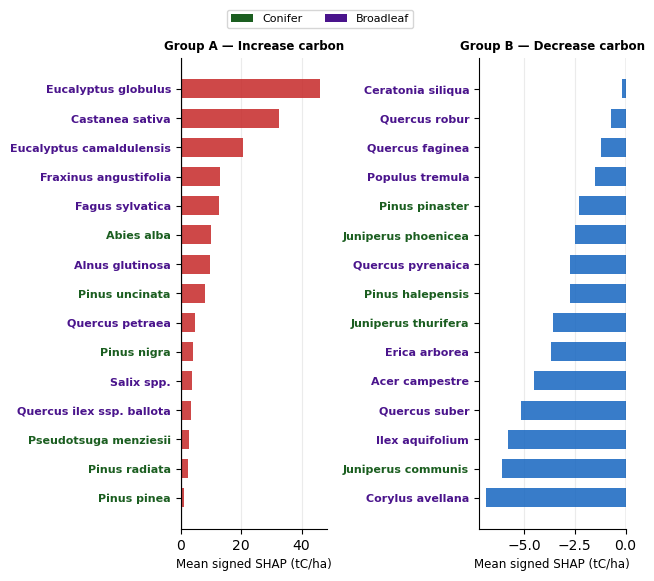

  -> species_LightGBM_local.png

CASO: IFN2 / carbono\_bruto4
  Registros IFN2: 43,539

  >>> LightGBM local (IFN2)
  Features: 126  |  esp_cols OHE: 66
  Test: 8,699 / 43,539 filas (20.0%)

  [TEST] LightGBM local (IFN2)  (8,699 filas)
  SHAP (tree) 12.1s  shape=(8699, 126)
  Positive: 22  |  Negative: 18
  [cache] guardado en LightGBM_local.joblib


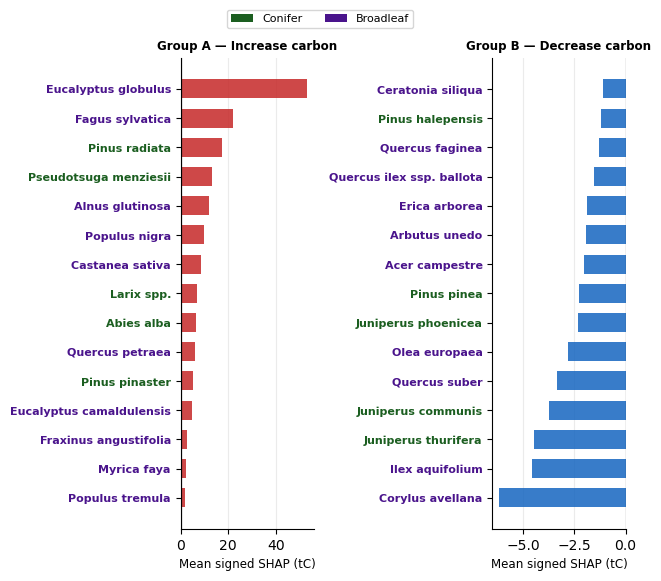

  -> species_LightGBM_local.png

CASO: IFN3 / c4
  Registros IFN3: 62,029

  >>> LightGBM local (IFN3)
  Features: 211  |  esp_cols OHE: 122
  Test: 12,332 / 62,029 filas (19.9%)

  [TEST] LightGBM local (IFN3)  (12,332 filas)
  SHAP (tree) 28.6s  shape=(12332, 211)
  Positive: 44  |  Negative: 21
  [cache] guardado en LightGBM_local.joblib


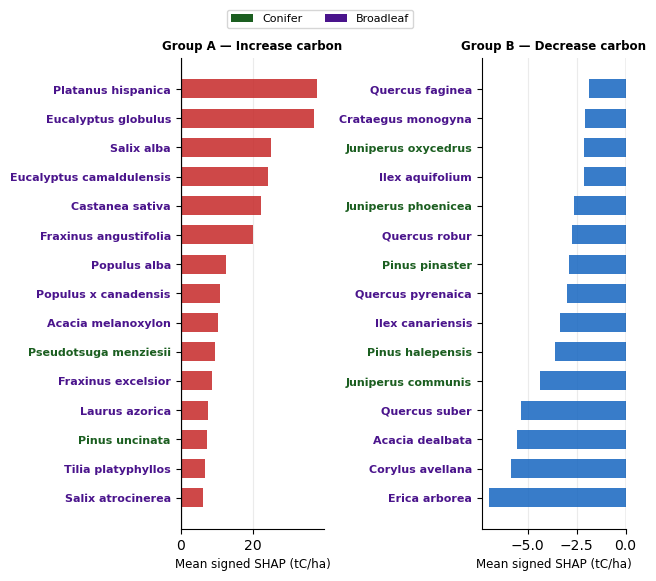

  -> species_LightGBM_local.png

CASO: IFN3 / carbono\_bruto4
  Registros IFN3: 89,580

  >>> LightGBM local (IFN3)
  Features: 210  |  esp_cols OHE: 129
  Test: 17,937 / 89,580 filas (20.0%)

  [TEST] LightGBM local (IFN3)  (17,937 filas)
  SHAP (tree) 41.5s  shape=(17937, 210)
  Positive: 48  |  Negative: 23
  [cache] guardado en LightGBM_local.joblib


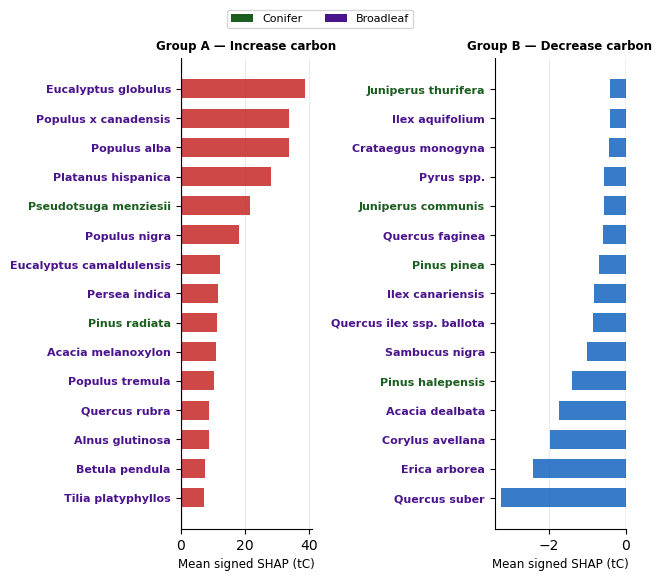

  -> species_LightGBM_local.png

CASO: IFN2+3 / c4
  Registros IFN2+3: 103,790

  >>> LightGBM global (IFN2+3)
  Features: 208  |  esp_cols OHE: 119
  Test: 20,605 / 103,790 filas (19.9%)

  [TEST] LightGBM global (IFN2+3)  (20,605 filas)
  SHAP (tree) 47.0s  shape=(20605, 208)
  Positive: 43  |  Negative: 21
  [cache] guardado en LightGBM_global.joblib


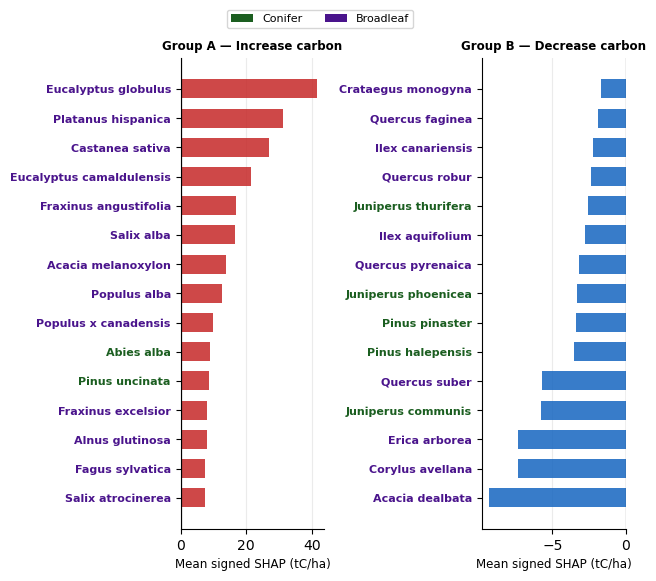

  -> species_LightGBM_global.png

  >>> GBDT global (IFN2+3)
  Features: 208  |  esp_cols OHE: 119
  Test: 20,605 / 103,790 filas (19.9%)

  [TEST] GBDT global (IFN2+3)  (20,605 filas)
  SHAP (tree) 293.8s  shape=(20605, 208)
  Positive: 67  |  Negative: 20
  [cache] guardado en GBDT_global.joblib


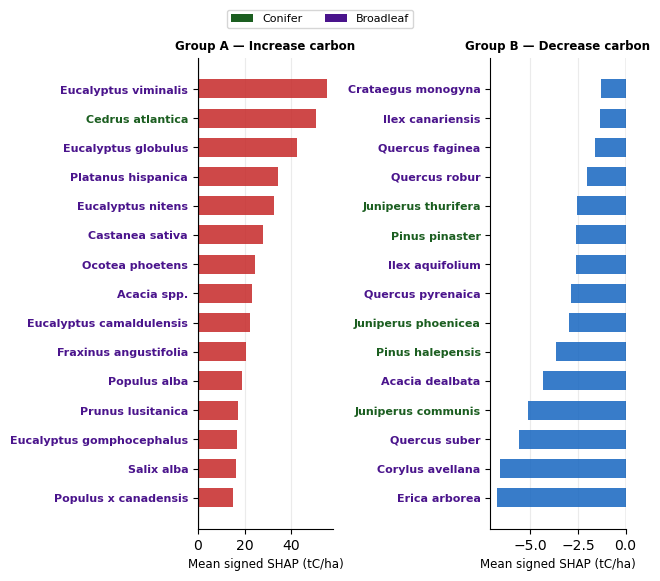

  -> species_GBDT_global.png

CASO: IFN2+3 / carbono\_bruto4
  Registros IFN2+3: 133,119

  >>> CatBoost global (IFN2+3)
  Features: 210  |  esp_cols OHE: 129
  Test: 26,664 / 133,119 filas (20.0%)

  [TEST] CatBoost global (IFN2+3)  (26,664 filas)
  SHAP (tree) 2.5s  shape=(26664, 210)
  Positive: 50  |  Negative: 21
  [cache] guardado en CatBoost_global.joblib


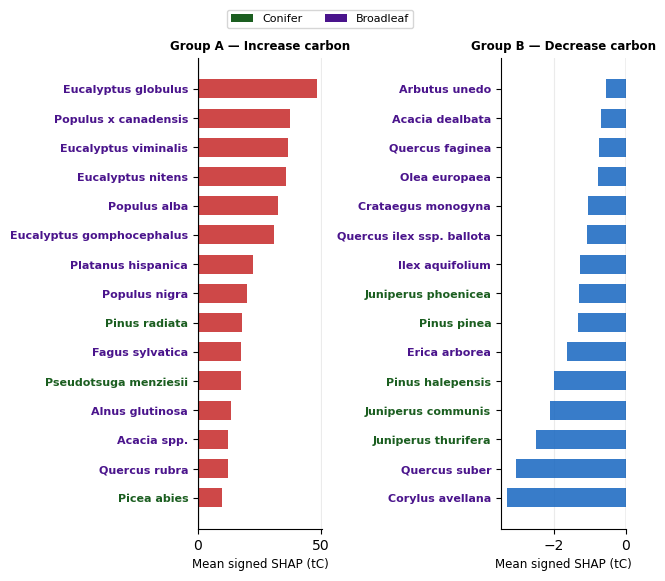

  -> species_CatBoost_global.png

  >>> LightGBM global (IFN2+3)
  Features: 210  |  esp_cols OHE: 129
  Test: 26,664 / 133,119 filas (20.0%)

  [TEST] LightGBM global (IFN2+3)  (26,664 filas)
  SHAP (tree) 37.1s  shape=(26664, 210)
  Positive: 45  |  Negative: 25
  [cache] guardado en LightGBM_global.joblib


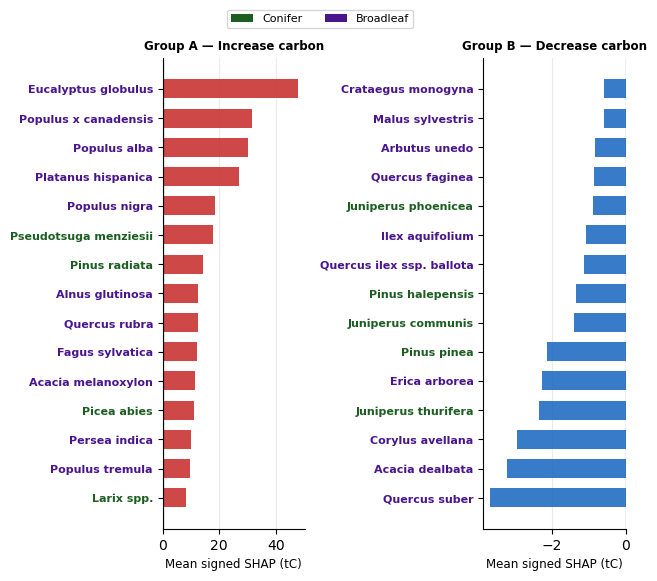

  -> species_LightGBM_global.png

Análisis de especies completado.


In [7]:
import time

FORCE_REGEN = True  # True → recomputa aunque existan caché y figura

# Modos de datos: 'full' usa todo el inventario, 'test' usa solo el conjunto de test
DATA_MODES = ['test']

df_full = pd.read_csv(DATA_PATH)
print(f'Dataset completo: {df_full.shape[0]:,} filas')

for caso in CASOS:
    titulo    = caso['titulo'].replace('\\\\', '')
    target    = caso['target']
    unit      = caso['unit']
    ifn_filt  = caso['ifn_filter']
    modelos   = caso['modelos']
    out_key   = caso['out_key']

    print(f'\n{"="*65}')
    print(f'CASO: {titulo}')
    print(f'{"="*65}')

    if ifn_filt:
        df_caso = df_full[df_full['ifn_id'].astype(str).str.contains(ifn_filt)].copy()
    else:
        df_caso = df_full.copy()
    if 'pendiente_cat'   in df_caso.columns:
        df_caso['pendiente_cat']   = df_caso['pendiente_cat'].map(MAPA_PENDIENTE)
    if 'orientacion_cat' in df_caso.columns:
        df_caso['orientacion_cat'] = df_caso['orientacion_cat'].map(MAPA_ORIENTACION)
    df_caso = df_caso[(df_caso[target].notna()) & (df_caso[target] != 0)].copy()
    if 'c' in df_caso.columns:
        df_caso = df_caso[(df_caso['c'].isna()) | (df_caso['c'] < df_caso[target])].copy()
    df_caso = df_caso[~(df_caso['fccarb'].notna() & (df_caso['fccarb'] < 20))].copy()
    lbl_ifn = ifn_filt if ifn_filt else '2+3'
    print(f'  Registros NFI{lbl_ifn}: {len(df_caso):,}')

    for mod in modelos:
        model_path = mod['path']
        model_name = mod['name']
        label      = mod['label']

        print(f'\n  >>> {label}')

        # Cargar pipeline y transformar una sola vez
        try:
            pipe_m  = joblib.load(model_path)
            model_m = pipe_m.named_steps['regressor']
            pre_m   = pipe_m.named_steps['preprocessor']

            feat_names = get_feature_names(pre_m)
            feat_cols  = [c for c in df_caso.columns if c not in (target, 'parcela_id')]
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                X_trans = pre_m.transform(df_caso[feat_cols])
            if X_trans.shape[1] != len(feat_names):
                feat_names = [f'f_{i:03d}' for i in range(X_trans.shape[1])]
            X_df_full = pd.DataFrame(X_trans, columns=feat_names)

            esp_cols = [(i, f) for i, f in enumerate(feat_names)
                        if f.startswith('especie_id_') or f == 'especie_id']
            esp_raw_full = df_caso['especie_id'].values
            print(f'  Features: {X_df_full.shape[1]}  |  esp_cols OHE: {len(esp_cols)}')

            # Nombres y tipo desde el catálogo de especies
            id_set = {
                str(int(float(f.replace('especie_id_','').replace('.0',''))))
                for _, f in esp_cols if '_' in f
            }
            if id_set:
                _ids = [int(i) for i in id_set]
                nombres_map = {i: NOMBRES_ESP[i] for i in _ids if i in NOMBRES_ESP}
                tipos_map   = {i: TIPOS_ESP[i] for i in _ids if i in TIPOS_ESP}
            else:
                nombres_map = {}; tipos_map = {}

            del pipe_m; gc.collect()

            # Obtener máscara de test
            idx_path = caso.get('test_idx_path')
            if idx_path and Path(idx_path).exists():
                import joblib as _jl
                te_idx = _jl.load(idx_path)
                te_mask = df_caso.index.isin(te_idx)
            else:
                from sklearn.model_selection import GroupShuffleSplit as _GSS
                _gss = _GSS(n_splits=1, test_size=0.2, random_state=42)
                _y   = df_caso[target].astype('float32')
                _X   = df_caso[[feat_cols[0]]].astype('float32')
                _, te_pos = next(_gss.split(_X, _y, groups=df_caso['parcela_id']))
                te_mask = np.zeros(len(df_caso), dtype=bool)
                te_mask[te_pos] = True

            print(f'  Test: {te_mask.sum():,} / {len(te_mask):,} filas ({te_mask.mean()*100:.1f}%)')

            for mode in DATA_MODES:
                if mode == 'test':
                    X_df     = X_df_full[te_mask].reset_index(drop=True)
                    esp_raw  = esp_raw_full[te_mask]
                    mode_sfx = '_test'
                else:
                    X_df     = X_df_full
                    esp_raw  = esp_raw_full
                    mode_sfx = ''

                mod_out_key = mod.get('out_key', out_key)
                out_dir    = OUT_DIR / f'{mod_out_key}{mode_sfx}'
                cache_path = CACHE_DIR / 'especies' / f'{out_key}{mode_sfx}' / f'{model_name}.joblib'
                save_p     = out_dir / f'species_{model_name}.png'

                print(f'\n  [{mode.upper()}] {label}  ({len(X_df):,} filas)')

                if cache_path.exists() and save_p.exists() and not FORCE_REGEN:
                    print(f'  [OK] caché y figura existen')
                    ipy_display(IPImage(str(save_p)))
                    continue

                analizar_especie_modelo(
                    pipe        = None,
                    model_m     = model_m,
                    model_name  = model_name,
                    model_label = f'{label} [{mode}]',
                    X_df        = X_df,
                    esp_raw     = esp_raw,
                    esp_cols    = esp_cols,
                    nombres_map = nombres_map,
                    tipos_map   = tipos_map,
                    titulo_caso = titulo,
                    unit        = unit,
                    out_dir     = out_dir,
                    cache_path  = cache_path,
                    force_regen = FORCE_REGEN,
                )

            del model_m, X_df_full, X_trans; gc.collect()

        except Exception as e:
            import traceback; traceback.print_exc()
            print(f'  ERROR: {type(e).__name__}: {e}')

print('\nAnálisis de especies completado.')


Casos:   0%|          | 0/6 [00:00<?, ?it/s]


CASO AVG (test): IFN2 / c4
  Registros: 41,761


  [cache] LightGBM
  [cache] XGBoost
  [cache] CatBoost
  [cache] GBDT
  [cache] MLP_PyTorch
  Promediando 5 modelos: LightGBM, XGBoost, CatBoost, GBDT, MLP_PyTorch


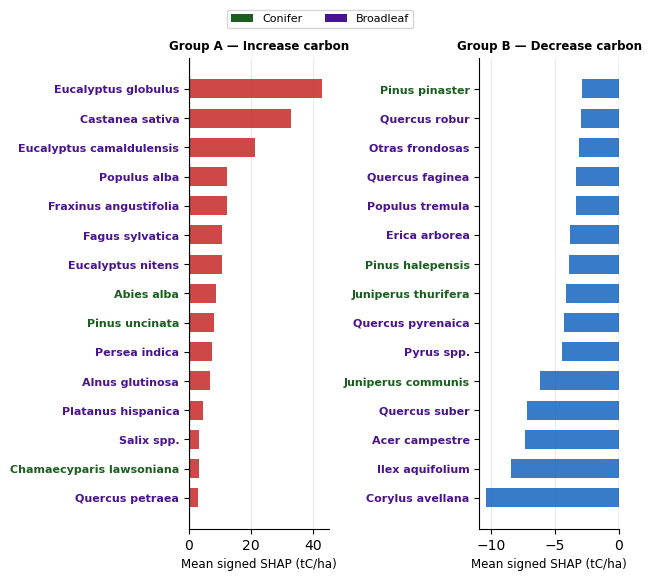

Casos:  17%|█▋        | 1/6 [00:00<00:04,  1.07it/s]

  -> species_avg.png

CASO AVG (test): IFN2 / carbono_bruto4
  Registros: 43,539


  [cache] LightGBM
  [cache] XGBoost
  [cache] CatBoost
  [cache] GBDT
  [cache] MLP_PyTorch
  Promediando 5 modelos: LightGBM, XGBoost, CatBoost, GBDT, MLP_PyTorch


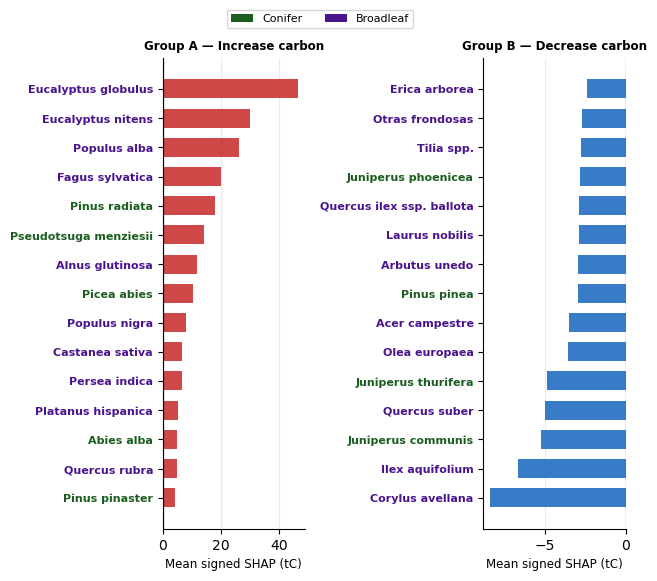

Casos:  33%|███▎      | 2/6 [00:01<00:03,  1.07it/s]

  -> species_avg.png

CASO AVG (test): IFN3 / c4
  Registros: 62,029


  [compute] LightGBM


  [cache] guardado LightGBM.joblib
  [compute] XGBoost


  [cache] guardado XGBoost.joblib
  [compute] CatBoost


  [cache] guardado CatBoost.joblib
  [compute] GBDT


  [cache] guardado GBDT.joblib
  [compute] MLP_PyTorch





















































































































































































































































































































































































PermutationExplainer explainer: 1765it [00:53, 28.81it/s]                          


  [cache] guardado MLP_PyTorch.joblib
  Promediando 5 modelos: LightGBM, XGBoost, CatBoost, GBDT, MLP_PyTorch


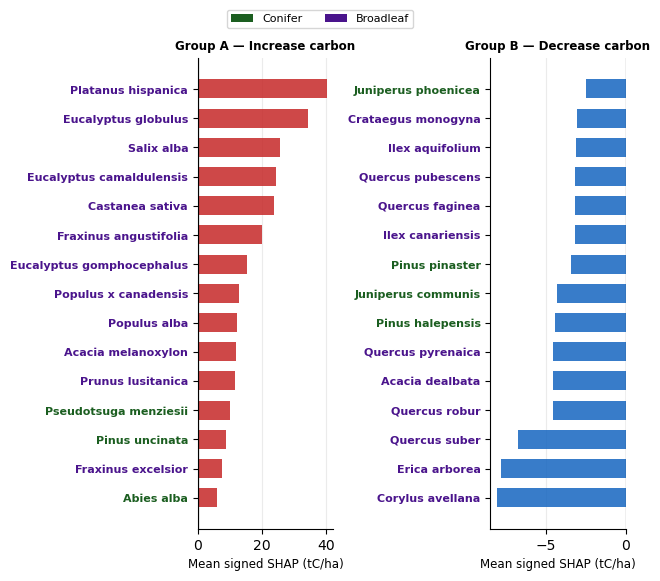

Casos:  50%|█████     | 3/6 [01:43<02:21, 47.02s/it]

  -> species_avg.png

CASO AVG (test): IFN3 / carbono_bruto4
  Registros: 89,580


  [compute] LightGBM


  [cache] guardado LightGBM.joblib
  [compute] XGBoost


  [cache] guardado XGBoost.joblib
  [compute] CatBoost


  [cache] guardado CatBoost.joblib
  [compute] GBDT


  [cache] guardado GBDT.joblib
  [compute] MLP_PyTorch












































































































































































































































































































































































PermutationExplainer explainer: 2001it [00:52, 31.27it/s]                          


  [cache] guardado MLP_PyTorch.joblib
  Promediando 5 modelos: LightGBM, XGBoost, CatBoost, GBDT, MLP_PyTorch


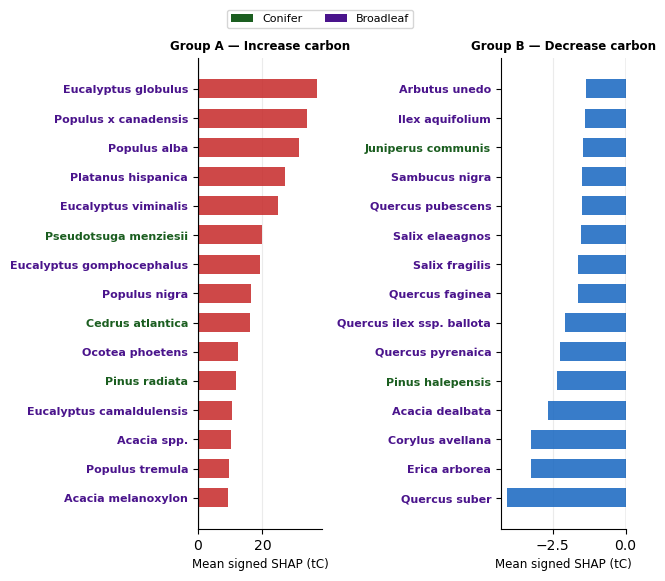

Casos:  67%|██████▋   | 4/6 [03:45<02:32, 76.43s/it]

  -> species_avg.png

CASO AVG (test): IFN2+3 / c4
  Registros: 103,790


  [compute] LightGBM


  [cache] guardado LightGBM.joblib
  [compute] XGBoost


  [cache] guardado XGBoost.joblib
  [compute] CatBoost


  [cache] guardado CatBoost.joblib
  [compute] GBDT


  [cache] guardado GBDT.joblib
  [compute] MLP_PyTorch






































































































































































































































































































































































































































































































PermutationExplainer explainer: 1851it [01:03, 24.44it/s]                          


  [cache] guardado MLP_PyTorch.joblib
  Promediando 5 modelos: LightGBM, XGBoost, CatBoost, GBDT, MLP_PyTorch


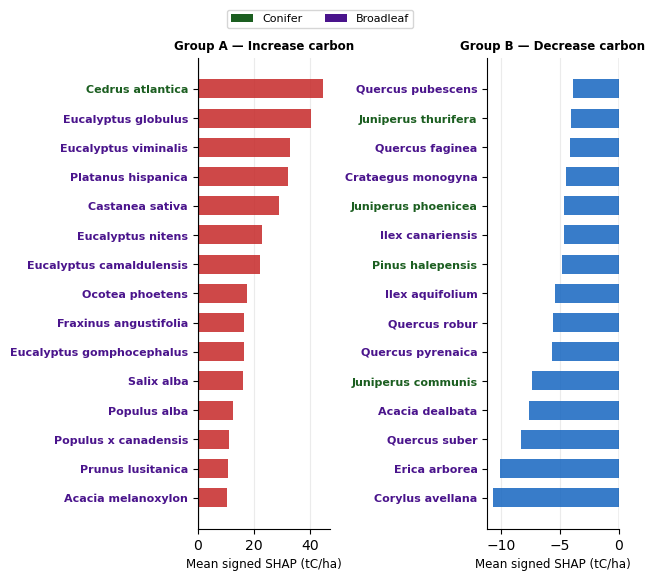

Casos:  83%|████████▎ | 5/6 [10:40<03:18, 198.73s/it]

  -> species_avg.png

CASO AVG (test): IFN2+3 / carbono_bruto4
  Registros: 133,119


  [compute] LightGBM


  [cache] guardado LightGBM.joblib
  [compute] XGBoost


  [cache] guardado XGBoost.joblib
  [compute] CatBoost


  [cache] guardado CatBoost.joblib
  [compute] GBDT


  [cache] guardado GBDT.joblib
  [compute] MLP_PyTorch














































































































































































































































































































































































































































PermutationExplainer explainer: 2001it [01:04, 26.37it/s]                          


  [cache] guardado MLP_PyTorch.joblib
  Promediando 5 modelos: LightGBM, XGBoost, CatBoost, GBDT, MLP_PyTorch


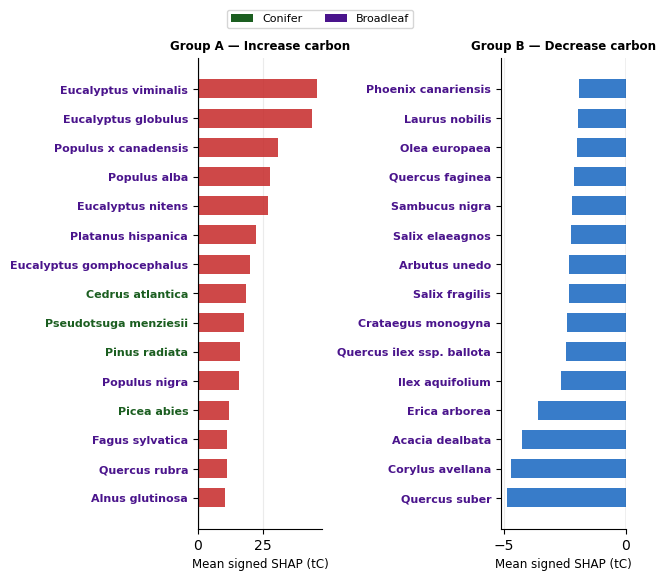

Casos: 100%|██████████| 6/6 [18:20<00:00, 183.41s/it]

  -> species_avg.png

Figuras de promedio de modelos completadas.


In [8]:
# =============================================================================
# Figura: media SHAP por especie promediada sobre los 5 modelos
# (una figura por combinación inventario x variable objetivo)
# =============================================================================

_AVG_MODE        = 'test'
_AVG_MODEL_NAMES = ['LightGBM', 'XGBoost', 'CatBoost', 'GBDT', 'MLP_PyTorch']
_AVG_FORCE_REGEN = False

_AVG_CASOS_DEF = [
    {'titulo': 'NFI2 / c4',              'target': 'c4',             'unit': 'tC/ha',
     'ifn_filter': '2',  'features': FEATURES_C4,  'out_key': 'IFN2_c4_avg',
     'model_dir': MODELS_IFN2_C4,
     'test_idx_path': BASE / 'models/artifacts/IFN2/c4/base/test_indices_real.joblib'},
    {'titulo': 'NFI2 / carbono_bruto4',   'target': 'carbono_bruto4', 'unit': 'tC',
     'ifn_filter': '2',  'features': FEATURES_CB4, 'out_key': 'IFN2_cb4_avg',
     'model_dir': MODELS_IFN2_CB4,
     'test_idx_path': BASE / 'models/artifacts/IFN2/carbono_bruto4/base/test_indices_real.joblib'},
    {'titulo': 'NFI3 / c4',              'target': 'c4',             'unit': 'tC/ha',
     'ifn_filter': '3',  'features': FEATURES_C4,  'out_key': 'IFN3_c4_avg',
     'model_dir': MODELS_IFN3_C4,
     'test_idx_path': BASE / 'models/artifacts/IFN3/c4/base/test_indices_real.joblib'},
    {'titulo': 'NFI3 / carbono_bruto4',   'target': 'carbono_bruto4', 'unit': 'tC',
     'ifn_filter': '3',  'features': FEATURES_CB4, 'out_key': 'IFN3_cb4_avg',
     'model_dir': MODELS_IFN3_CB4,
     'test_idx_path': BASE / 'models/artifacts/IFN3/carbono_bruto4/base/test_indices_real.joblib'},
    {'titulo': 'NFI2+3 / c4',            'target': 'c4',             'unit': 'tC/ha',
     'ifn_filter': None, 'features': FEATURES_C4,  'out_key': 'IFN23_c4_avg',
     'model_dir': MODELS_GLO_C4,
     'test_idx_path': None},
    {'titulo': 'NFI2+3 / carbono_bruto4', 'target': 'carbono_bruto4', 'unit': 'tC',
     'ifn_filter': None, 'features': FEATURES_CB4, 'out_key': 'IFN23_cb4_avg',
     'model_dir': MODELS_GLO_CB4,
     'test_idx_path': None},
]


def _compute_df_m_for_model(model_m, X_df, esp_raw_arr, esp_cols_loc, nombres_map, tipos_map):
    """Calcula df_m (SHAP por especie) sin generar figuras."""
    sv_m = None
    esp_raw_used = esp_raw_arr
    try:
        expl = shap.TreeExplainer(model_m)
        sv_m = expl.shap_values(X_df)
        if isinstance(sv_m, list): sv_m = sv_m[0]
    except Exception:
        idx_perm = _stratified_idx(esp_raw_arr, N_PER_ESP, SAMPLE_PERM)
        X_perm       = X_df.iloc[idx_perm].reset_index(drop=True)
        esp_raw_used = esp_raw_arr[idx_perm]
        feat_names_loc = list(X_df.columns)
        rng_bg = np.random.default_rng(99)
        bg_idx = rng_bg.choice(len(X_df), min(100, len(X_df)), replace=False)
        masker = shap.maskers.Independent(X_df.iloc[bg_idx], max_samples=100)
        def _predict_fn(X_in):
            return np.array(model_m.predict(pd.DataFrame(X_in, columns=feat_names_loc))).flatten().astype(float)
        expl_p = shap.Explainer(_predict_fn, masker, algorithm='permutation')
        sv_m   = expl_p(X_perm).values
        if isinstance(sv_m, list): sv_m = sv_m[0]

    rows = []
    for col_idx, col_name in esp_cols_loc:
        raw_id = col_name.replace('especie_id_', '').replace('.0', '')
        try:    esp_id = int(float(raw_id))
        except: esp_id = raw_id
        mask  = esp_raw_used == esp_id
        sv_col = sv_m[:, col_idx]
        rows.append({
            'especie_id'  : esp_id,
            'shap_abs'    : float(np.mean(np.abs(sv_col))),
            'shap_signed' : float(sv_col[mask].mean()) if mask.sum() > 0 else 0.0,
            'n_activo'    : int(mask.sum()),
        })
    df_m = (pd.DataFrame(rows).set_index('especie_id')
              .sort_values('shap_abs', ascending=False))
    df_m['nombre'] = df_m.index.map(nombres_map)
    df_m['tipo']   = df_m.index.map(tipos_map).fillna('?')
    del sv_m; gc.collect()
    return df_m


# ── Cargar datos si no están en memoria ──────────────────────────────────────
if 'df_full' not in dir() or df_full is None:
    df_full = pd.read_csv(DATA_PATH)
    print(f'Dataset: {df_full.shape[0]:,} filas')

_mode_sfx_avg = '_test' if _AVG_MODE == 'test' else ''

# ── Bucle principal ───────────────────────────────────────────────────────────
for caso in tqdm(_AVG_CASOS_DEF, desc='Casos'):
    titulo    = caso['titulo']
    target    = caso['target']
    unit      = caso['unit']
    ifn_filt  = caso['ifn_filter']
    features  = caso['features']
    out_key   = caso['out_key']
    model_dir = caso['model_dir']

    print(f'\n{"="*65}')
    print(f'CASO AVG ({_AVG_MODE}): {titulo}')
    print(f'{"="*65}')

    # ── Chequeo rápido: figura ya existe ─────────────────────────────────────
    out_dir_avg = OUT_DIR / f'{out_key}{_mode_sfx_avg}'
    save_path_avg = out_dir_avg / 'species_avg.png'
    if save_path_avg.exists() and not _AVG_FORCE_REGEN:
        # Verificar que todos los modelos tienen caché
        all_cached = all(
            (CACHE_DIR / 'especies' / f'{out_key}{_mode_sfx_avg}' / f'{mn}.joblib').exists()
            for mn in _AVG_MODEL_NAMES
            if (model_dir / f'{mn}.joblib').exists()
        )
        if all_cached:
            print('  [OK] figura y cachés existen — omitiendo')
            ipy_display(IPImage(str(save_path_avg)))
            continue

    # ── Preparar datos del caso ───────────────────────────────────────────────
    if ifn_filt:
        df_caso = df_full[df_full['ifn_id'].astype(str).str.contains(ifn_filt)].copy()
    else:
        df_caso = df_full.copy()
    for col, mapa in [('pendiente_cat', MAPA_PENDIENTE), ('orientacion_cat', MAPA_ORIENTACION)]:
        if col in df_caso.columns:
            df_caso[col] = df_caso[col].map(mapa)
    df_caso = df_caso[(df_caso[target].notna()) & (df_caso[target] != 0)].copy()
    if 'c' in df_caso.columns:
        df_caso = df_caso[(df_caso['c'].isna()) | (df_caso['c'] < df_caso[target])].copy()
    df_caso = df_caso[~(df_caso['fccarb'].notna() & (df_caso['fccarb'] < 20))].copy()
    feat_cols = [c for c in df_caso.columns if c not in (target, 'parcela_id')]
    print(f'  Registros: {len(df_caso):,}')

    # ── Máscara test (si aplica) ──────────────────────────────────────────────
    te_mask = None
    if _AVG_MODE == 'test':
        idx_path = caso.get('test_idx_path')
        if idx_path and Path(idx_path).exists():
            te_idx  = joblib.load(idx_path)
            te_mask = df_caso.index.isin(te_idx)
        else:
            _gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
            _y   = df_caso[target].astype('float32')
            _, te_pos = next(_gss.split(df_caso[[feat_cols[0]]], _y, groups=df_caso['parcela_id']))
            te_mask = np.zeros(len(df_caso), dtype=bool)
            te_mask[te_pos] = True

    # ── Recopilar df_m de cada modelo ────────────────────────────────────────
    df_models  = {}
    nombres_map = {}
    tipos_map   = {}
    _preprocessed = None  # cache del X_df_full transformado
    _esp_cols_ref  = None
    _esp_raw_full  = None

    for mname in tqdm(_AVG_MODEL_NAMES, desc=f'  Modelos ({titulo})', leave=False):
        model_path = model_dir / f'{mname}.joblib'
        cache_path = CACHE_DIR / 'especies' / f'{out_key}{_mode_sfx_avg}' / f'{mname}.joblib'

        # ── Cargar desde caché ────────────────────────────────────────────────
        if cache_path.exists() and not _AVG_FORCE_REGEN:
            print(f'  [cache] {mname}')
            df_m = joblib.load(cache_path)
            df_models[mname] = df_m
            # Tomar nombres_map y tipos_map del primer df_m disponible
            if not nombres_map:
                nombres_map = {k: v for k, v in df_m['nombre'].items() if pd.notna(v)}
            if not tipos_map and 'tipo' in df_m.columns:
                tipos_map = {k: v for k, v in df_m['tipo'].items()
                             if pd.notna(v) and v != '?'}
            continue

        if not model_path.exists():
            print(f'  [skip] {mname} — modelo no encontrado')
            continue

        print(f'  [compute] {mname}')
        try:
            pipe_m  = joblib.load(model_path)
            model_m = pipe_m.named_steps['regressor']
            pre_m   = pipe_m.named_steps['preprocessor']

            # Transformar datos una sola vez por caso (reusar si ya está hecho)
            if _preprocessed is None:
                feat_names = get_feature_names(pre_m)
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')
                    X_trans = pre_m.transform(df_caso[feat_cols])
                if X_trans.shape[1] != len(feat_names):
                    feat_names = [f'f_{i:03d}' for i in range(X_trans.shape[1])]
                _X_df_full_loc = pd.DataFrame(X_trans, columns=feat_names)
                _esp_cols_ref  = [(i, f) for i, f in enumerate(feat_names)
                                  if f.startswith('especie_id_') or f == 'especie_id']
                _esp_raw_full  = df_caso['especie_id'].values
                _preprocessed  = (_X_df_full_loc, feat_names)

                # Nombres y tipo desde el catálogo de especies
                id_set = {
                    str(int(float(f.replace('especie_id_', '').replace('.0', ''))))
                    for _, f in _esp_cols_ref if '_' in f
                }
                if id_set:
                    _ids = [int(i) for i in id_set]
                    nombres_map = {i: NOMBRES_ESP[i] for i in _ids if i in NOMBRES_ESP}
                    tipos_map   = {i: TIPOS_ESP[i] for i in _ids if i in TIPOS_ESP}
            else:
                _X_df_full_loc = _preprocessed[0]

            del pipe_m; gc.collect()

            # Seleccionar filas según modo
            if _AVG_MODE == 'test' and te_mask is not None:
                X_df    = _X_df_full_loc[te_mask].reset_index(drop=True)
                esp_raw = _esp_raw_full[te_mask]
            else:
                X_df    = _X_df_full_loc
                esp_raw = _esp_raw_full

            df_m = _compute_df_m_for_model(
                model_m, X_df, esp_raw, _esp_cols_ref, nombres_map, tipos_map
            )
            cache_path.parent.mkdir(parents=True, exist_ok=True)
            joblib.dump(df_m, cache_path, compress=3)
            print(f'  [cache] guardado {cache_path.name}')

            df_models[mname] = df_m
            del model_m; gc.collect()

        except Exception as e:
            import traceback; traceback.print_exc()
            print(f'  ERROR {mname}: {e}')

    if not df_models:
        print(f'  Sin modelos disponibles para {titulo}')
        continue

    # ── Promediar shap_signed por especie ─────────────────────────────────────
    all_signed = {}
    for mname, df_m in df_models.items():
        for esp_id, row in df_m.iterrows():
            all_signed.setdefault(esp_id, []).append(row['shap_signed'])

    avg_rows = []
    for esp_id, vals in all_signed.items():
        avg_rows.append({
            'especie_id'  : esp_id,
            'shap_signed' : float(np.mean(vals)),
            'n_models'    : len(vals),
            'nombre'      : nombres_map.get(esp_id, '?'),
            'tipo'        : tipos_map.get(esp_id, '?'),
        })
    df_avg = (pd.DataFrame(avg_rows)
                .set_index('especie_id')
                .sort_values('shap_signed', ascending=False))

    df_pos_avg = df_avg[df_avg['shap_signed'] > 0].sort_values('shap_signed', ascending=False)
    df_neg_avg = df_avg[df_avg['shap_signed'] < 0].sort_values('shap_signed', ascending=True)

    n_mod_used = len(df_models)
    mod_labels = ', '.join(df_models.keys())

    out_dir_avg.mkdir(parents=True, exist_ok=True)
    print(f'  Promediando {n_mod_used} modelos: {mod_labels}')
    plot_species_bars(
        df_pos_avg, df_neg_avg,
        titulo    = f'{titulo}\nMean across {n_mod_used} models: {mod_labels}',
        unit      = unit,
        save_path = save_path_avg,
        top_n     = TOP_PLOT,
    )

print('\nFiguras de promedio de modelos completadas.')


---
## Variable importance ranking across models and cases

For each of the 6 cases (IFN2/IFN3/IFN2+3 × c4/carbono_bruto4) and 5 model types (LightGBM, XGBoost, CatBoost, GBDT, MLP), SHAP values are computed and variables are grouped (OHE columns summed). Results are averaged across the 5 models to obtain a consensus ranking per case.

- **Absolute table**: mean rank by mean |SHAP| (1 = most important)
- **Signed tables**: mean SHAP value (with sign) split into positive and negative contributions

In [9]:
# =============================================================================
# Ranking absoluto: posición media por |SHAP| — 5 modelos × 6 casos
# =============================================================================
from sklearn.model_selection import GroupShuffleSplit

_N_SAMPLE = 2000
_N_BG     = 50

def _load_ifn_sample(target, features, ifn_filter, n_sample=2000, n_bg=50, seed=42):
    df = pd.read_csv(DATA_PATH)
    df['ifn_str'] = df['ifn_id'].astype(str)
    df = df[df['ifn_str'].str.contains(ifn_filter)].copy()
    if 'pendiente_cat'   in df.columns: df['pendiente_cat']   = df['pendiente_cat'].map(MAPA_PENDIENTE)
    if 'orientacion_cat' in df.columns: df['orientacion_cat'] = df['orientacion_cat'].map(MAPA_ORIENTACION)
    df = df[(df[target].notna()) & (df[target] != 0)].copy()
    if 'c' in df.columns:
        df = df[(df['c'].isna()) | (df['c'] < df[target])].copy()
    df = df[~(df['fccarb'].notna() & (df['fccarb'] < 20))].copy()
    tm = {col: df.groupby(col)[target].mean().to_dict()
          for col in VARS_CATEGORICAS if col in df.columns}
    present = [c for c in features if c in df.columns]
    X = df[present].copy().astype('float32')
    y = df[target].copy().astype('float32')
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    _, te_idx = next(gss.split(X, y, groups=df['parcela_id']))
    X_test = X.iloc[te_idx].copy()
    X_sample = X_test.sample(min(n_sample, len(X_test)), random_state=seed)
    X_bg_out = X_test.sample(min(n_bg,     len(X_test)), random_state=seed+1)
    print(f'  NFI{ifn_filter or "2+3"} / {target}: {len(X_test):,} test | muestra={len(X_sample)}')
    return X_sample, X_bg_out, tm

_RANK_MODELS = ['LightGBM', 'XGBoost', 'CatBoost', 'GBDT', 'MLP_PyTorch']

_RANK_CASOS = [
    {'label': 'NFI2 / c4',          'target': 'c4',             'ifn': '2', 'features': FEATURES_C4,  'model_dir': MODELS_IFN2_C4,  'cache_key': 'ifn2_c4'},
    {'label': 'NFI2 / carbono_b4',  'target': 'carbono_bruto4', 'ifn': '2', 'features': FEATURES_CB4, 'model_dir': MODELS_IFN2_CB4, 'cache_key': 'ifn2_cb4'},
    {'label': 'NFI3 / c4',          'target': 'c4',             'ifn': '3', 'features': FEATURES_C4,  'model_dir': MODELS_IFN3_C4,  'cache_key': 'ifn3_c4'},
    {'label': 'NFI3 / carbono_b4',  'target': 'carbono_bruto4', 'ifn': '3', 'features': FEATURES_CB4, 'model_dir': MODELS_IFN3_CB4, 'cache_key': 'ifn3_cb4'},
    {'label': 'NFI2+3 / c4',        'target': 'c4',             'ifn': '',  'features': FEATURES_C4,  'model_dir': MODELS_GLO_C4,   'cache_key': 'glo_c4'},
    {'label': 'NFI2+3 / carbono_b4','target': 'carbono_bruto4', 'ifn': '',  'features': FEATURES_CB4, 'model_dir': MODELS_GLO_CB4,  'cache_key': 'glo_cb4'},
]

# Almacena datos SHAP para reutilizar en celda de signo
_rank_shap_data = {}  # {caso_label: {mname: (shap_g, names_g)}}
all_ranks = {}

for caso in _RANK_CASOS:
    lbl = caso['label']
    print(f'\n── {lbl} ──')
    X_sample, X_bg, tm = _load_ifn_sample(
        caso['target'], caso['features'], caso['ifn'], _N_SAMPLE, _N_BG
    )
    var_ranks = {}
    _rank_shap_data[lbl] = {}

    for mname in _RANK_MODELS:
        model_path = caso['model_dir'] / f'{mname}.joblib'
        if not model_path.exists():
            print(f'  [SKIP] {mname}')
            continue
        cache_path = CACHE_DIR / caso['cache_key'] / f'{mname}_n{_N_SAMPLE}.joblib'
        try:
            sv, fn, Xt, Xr, bv = load_or_compute_shap(model_path, X_sample, X_bg, mname, cache_path=cache_path)
            shap_g, _, names_g = group_shap(sv, fn, Xr, Xt, tm)
            _rank_shap_data[lbl][mname] = (shap_g, names_g)
            mean_abs = np.abs(shap_g).mean(axis=0)
            order = np.argsort(-mean_abs)
            for rank_pos, j in enumerate(order, start=1):
                var_ranks.setdefault(names_g[j], []).append(rank_pos)
            print(f'  [OK] {mname}')
        except Exception as e:
            print(f'  [ERROR] {mname}: {e}')
        finally:
            gc.collect()

    all_ranks[lbl] = var_ranks

caso_labels = [c['label'] for c in _RANK_CASOS]
all_vars    = sorted(set(v for cr in all_ranks.values() for v in cr))

df_ranks = pd.DataFrame(index=all_vars, columns=caso_labels, dtype=float)
for lbl, var_ranks in all_ranks.items():
    for var, ranks in var_ranks.items():
        df_ranks.loc[var, lbl] = round(float(np.mean(ranks)), 1)

df_ranks.insert(0, 'Mean', df_ranks.mean(axis=1).round(1))
df_ranks = df_ranks.sort_values('Mean')

n_vars = len(df_ranks)
display(
    df_ranks.style
        .format('{:.1f}', na_rep='—')
        .background_gradient(cmap='RdYlGn_r', subset=caso_labels, vmin=1, vmax=n_vars)
        .background_gradient(cmap='RdYlGn_r', subset=['Mean'],     vmin=1, vmax=n_vars)
        .set_caption(
            f'Mean SHAP rank per variable across {len(_RANK_MODELS)} models '
            f'(LightGBM, XGBoost, CatBoost, GBDT, MLP)  |  '
            f'n={_N_SAMPLE} samples  |  rank 1 = most important'
        )
        .set_table_styles([{
            'selector': 'caption',
            'props': [('font-size', '12px'), ('font-weight', 'bold'), ('text-align', 'left')]
        }])
)



── IFN2 / c4 ──
  IFN2 / c4: 8,324 test | muestra=2000
[caché]   [OK] LightGBM
[caché]   [OK] XGBoost
[caché]   [OK] CatBoost
[caché]   [OK] GBDT
[caché]   [OK] MLP_PyTorch

── IFN2 / carbono_b4 ──
  IFN2 / carbono_bruto4: 8,699 test | muestra=2000
[caché]   [OK] LightGBM
[caché]   [OK] XGBoost
[caché]   [OK] CatBoost
[caché]   [OK] GBDT
[caché]   [OK] MLP_PyTorch

── IFN3 / c4 ──
  IFN3 / c4: 12,332 test | muestra=2000
[caché]   [OK] LightGBM
[caché]   [OK] XGBoost
[caché]   [OK] CatBoost
[caché]   [OK] GBDT
[caché]   [OK] MLP_PyTorch

── IFN3 / carbono_b4 ──
  IFN3 / carbono_bruto4: 17,937 test | muestra=2000
[caché]   [OK] LightGBM
[caché]   [OK] XGBoost
[caché]   [OK] CatBoost
[caché]   [OK] GBDT
[caché]   [OK] MLP_PyTorch

── IFN2+3 / c4 ──
  IFN2+3 / c4: 20,605 test | muestra=2000
[caché]   [OK] LightGBM
[caché]   [OK] XGBoost
[caché]   [OK] CatBoost
[caché]   [OK] GBDT
[caché]   [OK] MLP_PyTorch

── IFN2+3 / carbono_b4 ──
  IFN2+3 / carbono_bruto4: 26,664 test | muestra=2000
[c

,Mean,IFN2 / c4,IFN2 / carbono_b4,IFN3 / c4,IFN3 / carbono_b4,IFN2+3 / c4,IFN2+3 / carbono_b4
npies* (Density),1.0,1.0,1.0,1.0,1.0,1.0,1.0
especie_id*,2.2,2.0,2.0,2.2,2.8,2.2,2.2
ocupa,2.9,3.2,3.0,3.0,2.2,2.8,3.0
radio,4.2,4.2,4.2,4.2,4.0,4.2,4.4
gndvi_mean_verano,6.6,6.0,5.0,7.0,7.0,7.8,6.6
tipo_especie*,7.1,11.4,8.8,4.6,5.8,6.0,6.0
periodo_agrupado,8.4,12.8,8.2,10.8,8.6,5.2,5.0
skt_mean_verano,9.5,6.6,—,10.4,—,11.6,—
rocosidad_id*,11.0,8.8,7.6,17.6,12.0,10.6,9.4
fccarb,11.2,—,—,9.0,9.6,13.6,12.4


In [10]:
# =============================================================================
# Tablas de contribución media por especie (con signo)
# Para cada especie: mean SHAP de su columna OHE solo en muestras donde está
# activa (especie_id == X), promediado entre modelos y casos.
# =============================================================================

_species_signed = {}  # {caso_label: {especie_id: [mean_shap_modelo1, ...]}}

for caso in _RANK_CASOS:
    lbl = caso['label']
    esp_vals = {}

    for mname in _RANK_MODELS:
        cache_path = CACHE_DIR / caso['cache_key'] / f'{mname}_n{_N_SAMPLE}.joblib'
        if not cache_path.exists():
            continue
        try:
            d      = joblib.load(cache_path)
            sv     = d['shap_vals']    # (n_samples, n_features)
            fn     = d['feat_names']
            Xr     = d['X_raw_used']   # DataFrame con columna especie_id
        except Exception as e:
            print(f'  [SKIP] {lbl} / {mname}: {e}')
            continue

        esp_id_col = Xr['especie_id'].values if 'especie_id' in Xr.columns else None

        for i, fname in enumerate(fn):
            if not (fname.startswith('especie_id_') or fname == 'especie_id'):
                continue
            raw_id = fname.replace('especie_id_', '').replace('.0', '')
            try:
                esp_id = int(float(raw_id))
            except Exception:
                continue

            # Solo muestras donde esa especie está activa
            if esp_id_col is not None:
                mask = (esp_id_col == esp_id)
            else:
                mask = np.ones(sv.shape[0], dtype=bool)

            if mask.sum() == 0:
                continue

            mean_sv = float(sv[mask, i].mean())
            esp_vals.setdefault(esp_id, []).append(mean_sv)

    _species_signed[lbl] = {k: float(np.mean(v)) for k, v in esp_vals.items()}
    print(f'  {lbl}: {len(_species_signed[lbl])} especies')

# ── Nombres desde el catálogo, tipo desde el CSV ─────────────────────────────
_all_ids = sorted(set(eid for d in _species_signed.values() for eid in d))
if _all_ids:
    _nombres = {i: NOMBRES_ESP[i] for i in _all_ids if i in NOMBRES_ESP}
else:
    _nombres = {}

# tipo_especie desde CSV: 0=Conífera, 1=Frondosa
_df_tipo  = pd.read_csv(DATA_PATH, usecols=['especie_id', 'tipo_especie']).drop_duplicates('especie_id')
_tipo_map = dict(zip(_df_tipo['especie_id'], _df_tipo['tipo_especie']))
_TIPO_LBL = {0: 'Conífera', 1: 'Frondosa'}

# ── Construir DataFrame ───────────────────────────────────────────────────────
_caso_labels = [c['label'] for c in _RANK_CASOS]
df_esp_signed = pd.DataFrame(index=_all_ids, columns=_caso_labels, dtype=float)
for lbl, vdict in _species_signed.items():
    for esp_id, val in vdict.items():
        df_esp_signed.loc[esp_id, lbl] = round(val, 3)

df_esp_signed['Mean'] = df_esp_signed[_caso_labels].mean(axis=1).round(3)
_ids_ord = list(df_esp_signed.index)
df_esp_signed.insert(0, 'Tipo', [_TIPO_LBL.get(_tipo_map.get(i), '?') for i in _ids_ord])
df_esp_signed = df_esp_signed[['Tipo', 'Mean'] + _caso_labels]
df_esp_signed.index = [_nombres.get(i, '?') for i in _ids_ord]

df_esp_pos = df_esp_signed[df_esp_signed['Mean'] > 0].sort_values('Mean', ascending=False)
df_esp_neg = df_esp_signed[df_esp_signed['Mean'] < 0].sort_values('Mean', ascending=True)

_num_cols = ['Mean'] + _caso_labels

# ── Tabla 1: especies que aumentan la predicción ──────────────────────────────
print(f'\nEspecies con contribución POSITIVA: {len(df_esp_pos)}')
display(
    df_esp_pos.style
        .format('{:+.3f}', na_rep='—', subset=_num_cols)
        .background_gradient(cmap='Greens', subset=_num_cols, vmin=0)
        .set_caption(
            f'Species positive SHAP contribution — mean over active samples and {len(_RANK_MODELS)} models '            f'(n={_N_SAMPLE} samples per case)'
        )
        .set_table_styles([{'selector': 'caption',
                            'props': [('font-size', '12px'), ('font-weight', 'bold'),
                                      ('text-align', 'left')]}])
)

# ── Tabla 2: especies que disminuyen la predicción ────────────────────────────
print(f'Especies con contribución NEGATIVA: {len(df_esp_neg)}')
display(
    df_esp_neg.style
        .format('{:+.3f}', na_rep='—', subset=_num_cols)
        .background_gradient(cmap='Reds_r', subset=_num_cols, vmax=0)
        .set_caption(
            f'Species negative SHAP contribution — mean over active samples and {len(_RANK_MODELS)} models '            f'(n={_N_SAMPLE} samples per case)'
        )
        .set_table_styles([{'selector': 'caption',
                            'props': [('font-size', '12px'), ('font-weight', 'bold'),
                                      ('text-align', 'left')]}])
)


  IFN2 / c4: 54 especies
  IFN2 / carbono_b4: 54 especies
  IFN3 / c4: 76 especies
  IFN3 / carbono_b4: 89 especies
  IFN2+3 / c4: 73 especies
  IFN2+3 / carbono_b4: 77 especies

Especies con contribución POSITIVA: 56


,Tipo,Mean,IFN2 / c4,IFN2 / carbono_b4,IFN3 / c4,IFN3 / carbono_b4,IFN2+3 / c4,IFN2+3 / carbono_b4
Eucalyptus globulus,Frondosa,+41.992,+43.104,+46.960,+35.282,+37.835,+41.967,+46.803
Populus alba,Frondosa,+27.141,+13.585,+28.390,+16.593,+52.001,+19.916,+32.362
Populus x canadensis,Frondosa,+24.346,—,—,+12.369,+36.126,+17.049,+31.838
Eucalyptus nitens,Frondosa,+22.161,—,+35.687,—,+7.380,—,+23.417
Eucalyptus gomphocephalus,Frondosa,+17.956,—,—,+17.956,—,—,—
Castanea sativa,Frondosa,+17.354,+31.475,+8.646,+28.718,+1.745,+28.375,+5.164
Ocotea phoetens,Frondosa,+16.813,—,—,—,—,+16.813,—
Platanus hispanica,Frondosa,+16.573,+1.892,+4.112,—,+30.437,—,+29.852
Acacia melanoxylon,Frondosa,+16.509,—,—,—,—,+16.509,—
Cedrus atlantica,Conífera,+15.817,—,—,—,—,—,+15.817


Especies con contribución NEGATIVA: 38


,Tipo,Mean,IFN2 / c4,IFN2 / carbono_b4,IFN3 / c4,IFN3 / carbono_b4,IFN2+3 / c4,IFN2+3 / carbono_b4
Corylus avellana,Frondosa,-7.593,-9.727,-7.457,-7.653,-1.673,-14.620,-4.431
Quercus suber,Frondosa,-5.933,-7.628,-4.834,-5.438,-5.861,-7.621,-4.215
Quercus pyrenaica,Frondosa,-4.021,-5.884,-1.323,-5.078,-4.315,-6.187,-1.339
Ilex aquifolium,Frondosa,-3.930,-7.136,-4.624,-1.331,-1.761,-5.206,-3.522
Juniperus communis,Conífera,-3.686,-5.135,-5.191,-2.701,-2.127,-5.669,-1.290
Erica arborea,Frondosa,-3.571,-1.686,-1.817,-5.496,-3.108,-7.519,-1.802
Juniperus thurifera,Conífera,-3.502,-5.626,-4.791,-1.753,-1.487,-5.451,-1.903
Pinus halepensis,Conífera,-3.345,-4.106,-2.657,-4.497,-2.663,-4.921,-1.224
Quercus faginea,Frondosa,-2.908,-3.732,-2.323,-3.161,-1.908,-4.278,-2.047
Quercus robur,Frondosa,-2.488,-4.146,-0.949,-3.989,-0.990,-4.964,+0.111


In [11]:
# =============================================================================
# Top 10 positivas + Top 10 negativas — tabla combinada y LaTeX
# =============================================================================

_TOP_N = 10

df_top_pos = df_esp_pos.head(_TOP_N)
df_top_neg = df_esp_neg.head(_TOP_N)

# ── Tabla combinada con separador visual ─────────────────────────────────────
# Añadir columna de grupo para poder colorear
df_top_pos = df_top_pos.copy(); df_top_pos['_group'] = 'pos'
df_top_neg = df_top_neg.copy(); df_top_neg['_group'] = 'neg'

df_combined = pd.concat([df_top_pos, df_top_neg])
_num_cols  = ['Mean'] + _caso_labels
_data_cols = ['Tipo', 'Mean'] + _caso_labels

_groups = df_combined['_group']

def _highlight_group(row):
    g = _groups.loc[row.name]
    if g == 'pos':
        return ['background-color: #fce4e4'] * len(row)
    else:
        return ['background-color: #e3eefa'] * len(row)

display(
    df_combined[_data_cols].style
        .apply(_highlight_group, axis=1)
        .format('{:+.3f}', na_rep='—', subset=_num_cols)
        .set_caption(
            f'Top {_TOP_N} species increasing (red) and decreasing (blue) carbon prediction '
            f'— mean signed SHAP over active samples and {len(_RANK_MODELS)} models'
        )
        .set_table_styles([{'selector': 'caption',
                            'props': [('font-size', '12px'), ('font-weight', 'bold'),
                                      ('text-align', 'left')]}])
)

# ── LaTeX (booktabs) ─────────────────────────────────────────────────────────
# Acortar nombres de columnas para LaTeX
_col_rename = {
    'NFI2 / c4':             r'NFI2\,c4',
    'NFI2 / cb4':            r'NFI2\,cb4',
    'NFI3 / c4':             r'NFI3\,c4',
    'NFI3 / cb4':            r'NFI3\,cb4',
    'NFI2+3 / c4':           r'NFI23\,c4',
    'NFI2+3 / cb4':          r'NFI23\,cb4',
    'Mean':                  r'\textbf{Mean}',
}

def _to_latex_top10(df_pos, df_neg, top_n=10):
    rows_pos = df_pos.head(top_n)
    rows_neg = df_neg.head(top_n)

    def _fmt_name(s):
        return str(s).replace('_', r'\_')

    all_cols = ['Mean'] + _caso_labels
    col_hdrs = [_col_rename.get(col, col) for col in all_cols]
    n_cols   = len(all_cols)
    # Tipo column (text) + Species + numeric cols
    col_spec  = 'l' + 'l' + 'r' * n_cols

    def _block(df_block, group_label):
        lines = []
        lines.append(r'\multicolumn{' + str(n_cols + 2) + r'}{l}{'
                      r'\textit{' + group_label + r'}} \\')
        lines.append(r'\midrule')
        for idx, row in df_block.iterrows():
            name = _fmt_name(str(idx))
            tipo = str(row.get('Tipo', '?'))
            vals = []
            for col in all_cols:
                v = row.get(col, float('nan'))
                vals.append(f'{v:+.3f}' if pd.notna(v) else '—')
            lines.append(tipo + ' & ' + name + ' & ' + ' & '.join(vals) + r' \\')
        return lines

    latex_lines = [
        r'\begin{table}[ht]',
        r'\centering',
        r'\small',
        r'\caption{Top ' + str(top_n) + r' species with highest (positive) and lowest (negative) '
        r'mean signed SHAP contribution across ' + str(len(_RANK_MODELS)) + r' models.}',
        r'\label{tab:top_species_shap}',
        r'\begin{tabular}{' + col_spec + '}',
        r'\toprule',
        r'Tipo & Species & ' + ' & '.join(col_hdrs) + r' \\',
        r'\midrule',
    ]
    latex_lines += _block(rows_pos, 'Top ' + str(top_n) + ' — increases carbon prediction')
    latex_lines.append(r'\midrule')
    latex_lines += _block(rows_neg, 'Top ' + str(top_n) + ' — decreases carbon prediction')
    latex_lines += [
        r'\bottomrule',
        r'\end{tabular}',
        r'\end{table}',
    ]
    return '\n'.join(latex_lines)


_latex_top10 = _to_latex_top10(df_esp_pos, df_esp_neg, top_n=_TOP_N)
print(_latex_top10)


,Tipo,Mean,IFN2 / c4,IFN2 / carbono_b4,IFN3 / c4,IFN3 / carbono_b4,IFN2+3 / c4,IFN2+3 / carbono_b4
Eucalyptus globulus,Frondosa,+41.992,+43.104,+46.960,+35.282,+37.835,+41.967,+46.803
Populus alba,Frondosa,+27.141,+13.585,+28.390,+16.593,+52.001,+19.916,+32.362
Populus x canadensis,Frondosa,+24.346,—,—,+12.369,+36.126,+17.049,+31.838
Eucalyptus nitens,Frondosa,+22.161,—,+35.687,—,+7.380,—,+23.417
Eucalyptus gomphocephalus,Frondosa,+17.956,—,—,+17.956,—,—,—
Castanea sativa,Frondosa,+17.354,+31.475,+8.646,+28.718,+1.745,+28.375,+5.164
Ocotea phoetens,Frondosa,+16.813,—,—,—,—,+16.813,—
Platanus hispanica,Frondosa,+16.573,+1.892,+4.112,—,+30.437,—,+29.852
Acacia melanoxylon,Frondosa,+16.509,—,—,—,—,+16.509,—
Cedrus atlantica,Conífera,+15.817,—,—,—,—,—,+15.817


\begin{table}[ht]
\centering
\small
\caption{Top 10 species with highest (positive) and lowest (negative) mean signed SHAP contribution across 5 models.}
\label{tab:top_species_shap}
\begin{tabular}{llrrrrrrr}
\toprule
Tipo & Species & \textbf{Mean} & IFN2\,c4 & IFN2 / carbono_b4 & IFN3\,c4 & IFN3 / carbono_b4 & IFN23\,c4 & IFN2+3 / carbono_b4 \\
\midrule
\multicolumn{9}{l}{\textit{Top 10 — increases carbon prediction}} \\
\midrule
Frondosa & Eucalyptus globulus & +41.992 & +43.104 & +46.960 & +35.282 & +37.835 & +41.967 & +46.803 \\
Frondosa & Populus alba & +27.141 & +13.585 & +28.390 & +16.593 & +52.001 & +19.916 & +32.362 \\
Frondosa & Populus x canadensis & +24.346 & — & — & +12.369 & +36.126 & +17.049 & +31.838 \\
Frondosa & Eucalyptus nitens & +22.161 & — & +35.687 & — & +7.380 & — & +23.417 \\
Frondosa & Eucalyptus gomphocephalus & +17.956 & — & — & +17.956 & — & — & — \\
Frondosa & Castanea sativa & +17.354 & +31.475 & +8.646 & +28.718 & +1.745 & +28.375 & +5.164 \\
Frondosa &

In [13]:
# =============================================================================
# Exportación LaTeX de las tablas de ranking SHAP (requiere cell-ranking-abs
# y cell-ranking-signed ejecutadas previamente)
# =============================================================================

def _fmt_rank(v):
    if pd.isna(v): return '---'
    return f'{v:.0f}' if v == int(v) else f'{v:.1f}'

def _fmt_shap(v):
    if pd.isna(v): return '---'
    return f'{v:+.3f}'

def _escape(s):
    return s.replace('_', r'\_').replace('%', r'\%').replace('&', r'\&')

def table_to_latex(df, fmt_fn, caption, label, bold_min=True, bold_max=False):
    cols = list(df.columns)
    col_fmt = 'l' + 'r' * len(cols)
    lines = []
    lines.append(r'\begin{table}[htbp]')
    lines.append(r'  \centering')
    lines.append(r'  \footnotesize')
    lines.append(f'  \\caption{{{caption}}}')
    lines.append(f'  \\label{{tab:{label}}}')
    lines.append(f'  \\begin{{tabular}}{{{col_fmt}}}')
    lines.append(r'    \toprule')
    header = ['Variable'] + [f'\\textbf{{{_escape(c)}}}' for c in cols]
    lines.append('    ' + ' & '.join(header) + r' \\')
    lines.append(r'    \midrule')
    bold_vals = {}
    for c in cols:
        col_data = df[c].dropna()
        if len(col_data) == 0: continue
        if bold_min:  bold_vals[c] = col_data.min()
        elif bold_max: bold_vals[c] = col_data.abs().max()
    for var, row in df.iterrows():
        parts = [_escape(str(var))]
        for c in cols:
            val = row[c]
            cs = fmt_fn(val)
            if not pd.isna(val) and c in bold_vals:
                if bold_min and abs(val - bold_vals[c]) < 1e-6:
                    cs = f'\\textbf{{{cs}}}'
                elif bold_max and abs(abs(val) - bold_vals[c]) < 1e-6:
                    cs = f'\\textbf{{{cs}}}'
            parts.append(cs)
        lines.append('    ' + ' & '.join(parts) + r' \\')
    lines.append(r'    \bottomrule')
    lines.append(r'  \end{tabular}')
    lines.append(r'\end{table}')
    return '\n'.join(lines)


# ── Tabla: ranking absoluto ───────────────────────────────────────────────────
print('% ============================================================')
print('% Tabla: Ranking medio de variables por |SHAP|')
print('% ============================================================')
print(table_to_latex(
    df_ranks,
    fmt_fn   = _fmt_rank,
    caption  = 'Mean SHAP rank per variable across LightGBM, XGBoost, CatBoost, GBDT and MLP '
               f'(n={_N_SAMPLE} samples; rank 1 = most important).',
    label    = 'shap_rank_abs_esp',
    bold_min = True,
))

print()

# ── Tablas: contribuciones con signo ──────────────────────────────────────────
for _df, _lbl, _cap in [
    (df_esp_pos.select_dtypes(include='number'), 'shap_rank_pos_esp',
     'Variables with positive mean SHAP contribution (averaged across models; '
     'higher = pushes prediction up more).'),
    (df_esp_neg.select_dtypes(include='number'), 'shap_rank_neg_esp',
     'Variables with negative mean SHAP contribution (averaged across models; '
     'more negative = pushes prediction down more).'),
]:
    print(f'% ============================================================')
    print(f'% Tabla: {_lbl}')
    print(f'% ============================================================')
    print(table_to_latex(
        _df,
        fmt_fn   = _fmt_shap,
        caption  = _cap,
        label    = _lbl,
        bold_min = False,
        bold_max = True,
    ))
    print()


% ============================================================
% Tabla: Ranking medio de variables por |SHAP|
% ============================================================
\begin{table}[htbp]
  \centering
  \footnotesize
  \caption{Mean SHAP rank per variable across LightGBM, XGBoost, CatBoost, GBDT and MLP (n=2000 samples; rank 1 = most important).}
  \label{tab:shap_rank_abs_esp}
  \begin{tabular}{lrrrrrrr}
    \toprule
    Variable & \textbf{Mean} & \textbf{IFN2 / c4} & \textbf{IFN2 / carbono\_b4} & \textbf{IFN3 / c4} & \textbf{IFN3 / carbono\_b4} & \textbf{IFN2+3 / c4} & \textbf{IFN2+3 / carbono\_b4} \\
    \midrule
    npies* (Density) & \textbf{1} & \textbf{1} & \textbf{1} & \textbf{1} & \textbf{1} & \textbf{1} & \textbf{1} \\
    especie\_id* & 2.2 & 2 & 2 & 2.2 & 2.8 & 2.2 & 2.2 \\
    ocupa & 2.9 & 3.2 & 3 & 3 & 2.2 & 2.8 & 3 \\
    radio & 4.2 & 4.2 & 4.2 & 4.2 & 4 & 4.2 & 4.4 \\
    gndvi\_mean\_verano & 6.6 & 6 & 5 & 7 & 7 & 7.8 & 6.6 \\
    tipo\_especie* & 7.1 & 11.4 & 8